In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
sns.set_theme(style="whitegrid")

In [10]:
df = pd.read_csv("winequality-white.csv", sep=";")

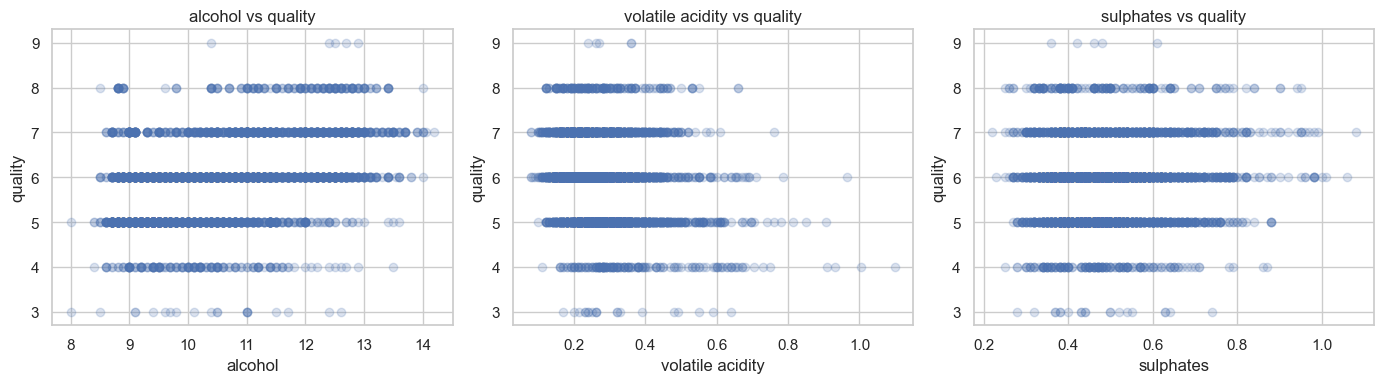

In [11]:
features = ["alcohol", "volatile acidity", "sulphates"]
target = "quality"
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, feature in zip(axes, features):
    ax.scatter(df[feature], df[target], alpha=0.2)
    ax.set_xlabel(feature)
    ax.set_ylabel(target)
    ax.set_title(f"{feature} vs quality")
plt.tight_layout()
plt.show()

In [12]:
print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
display(df.head())
print("\nDataset Information:")
df.info()
print("\nStatistical Summary:")
display(df.describe())

Dataset Shape: (4898, 12)

First 5 Rows:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4898 entries, 0 to 4897
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         4898 non-null   float64
 1   volatile acidity      4898 non-null   float64
 2   citric acid           4898 non-null   float64
 3   residual sugar        4898 non-null   float64
 4   chlorides             4898 non-null   float64
 5   free sulfur dioxide   4898 non-null   float64
 6   total sulfur dioxide  4898 non-null   float64
 7   density               4898 non-null   float64
 8   pH                    4898 non-null   float64
 9   sulphates             4898 non-null   float64
 10  alcohol               4898 non-null   float64
 11  quality               4898 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 459.3 KB

Statistical Summary:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000
mean,6.854788,0.278241,0.334192,6.391415,0.045772,35.308085,138.360657,0.994027,3.188267,0.489847,10.514267,5.877909
std,0.843868,0.100795,0.121020,5.072058,0.021848,17.007137,42.498065,0.002991,0.151001,0.114126,1.230621,0.885639
min,3.800000,0.080000,0.000000,0.600000,0.009000,2.000000,9.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.300000,0.210000,0.270000,1.700000,0.036000,23.000000,108.000000,0.991723,3.090000,0.410000,9.500000,5.000000
50%,6.800000,0.260000,0.320000,5.200000,0.043000,34.000000,134.000000,0.993740,3.180000,0.470000,10.400000,6.000000
75%,7.300000,0.320000,0.390000,9.900000,0.050000,46.000000,167.000000,0.996100,3.280000,0.550000,11.400000,6.000000
max,14.200000,1.100000,1.660000,65.800000,0.346000,289.000000,440.000000,1.038980,3.820000,1.080000,14.200000,9.000000


In [13]:
print("Missing Values:")
display(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nColumn Names:")
print(df.columns.tolist())

Missing Values:


fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64


Duplicate Rows: 937

Column Names:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']


In [14]:
print("Before removing duplicates:", df.shape)
df = df.drop_duplicates().reset_index(drop=True)
print("After removing duplicates:", df.shape)

Before removing duplicates: (4898, 12)
After removing duplicates: (3961, 12)


Wine Quality Distribution:


quality
3      20
4     153
5    1175
6    1788
7     689
8     131
9       5
Name: count, dtype: int64

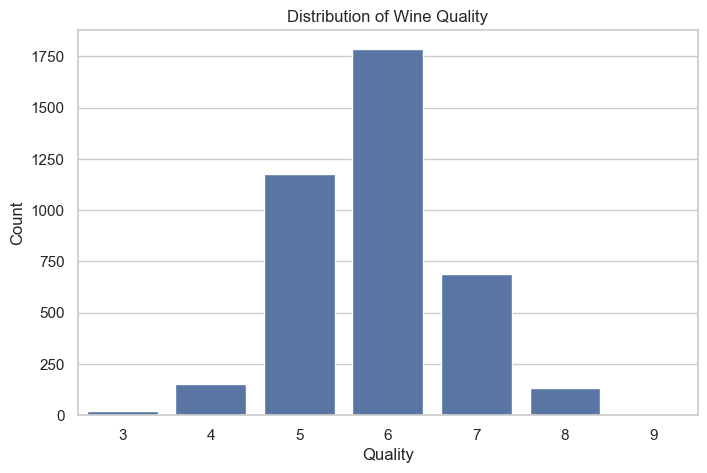

In [16]:
print("Wine Quality Distribution:")
display(df["quality"].value_counts().sort_index())
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="quality")
plt.title("Distribution of Wine Quality")
plt.xlabel("Quality")
plt.ylabel("Count")
plt.show()

In [18]:
features = ["alcohol", "volatile acidity", "sulphates"]
target = "quality"
X = df[features]
y = df[target]
print("Input Features:", features)
print("Target:", target)
print("X Shape:", X.shape)
print("y Shape:", y.shape)

Input Features: ['alcohol', 'volatile acidity', 'sulphates']
Target: quality
X Shape: (3961, 3)
y Shape: (3961,)


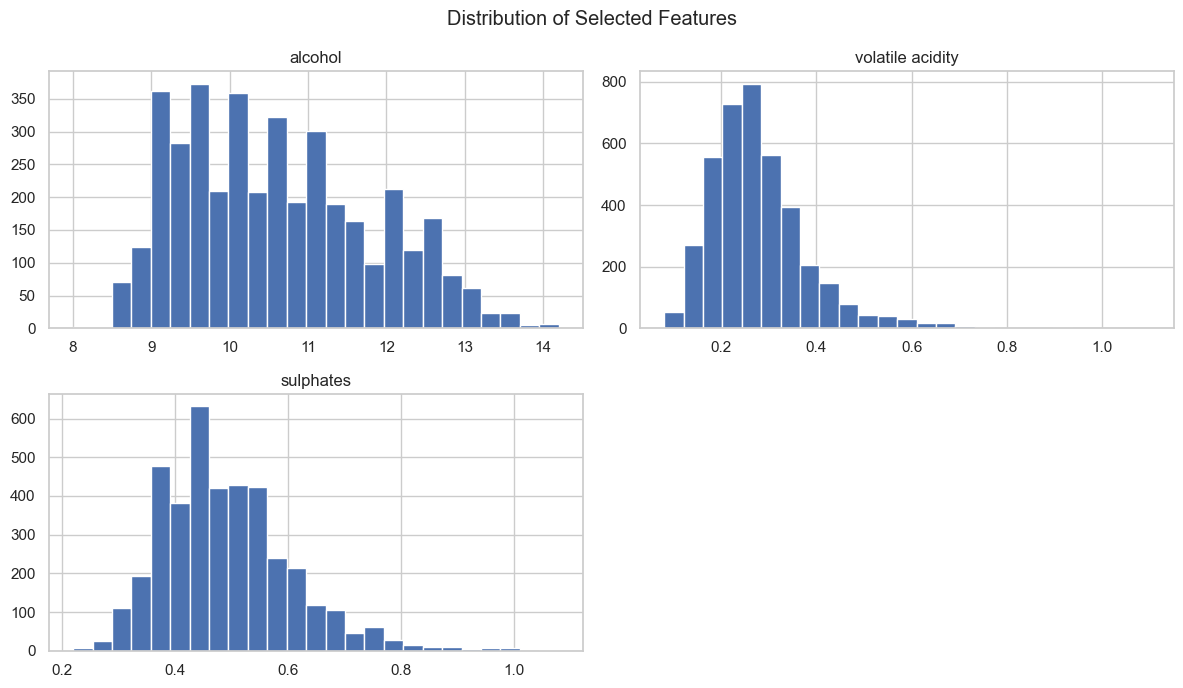

In [19]:
X.hist(figsize=(12, 7), bins=25)
plt.suptitle("Distribution of Selected Features")
plt.tight_layout()
plt.show()

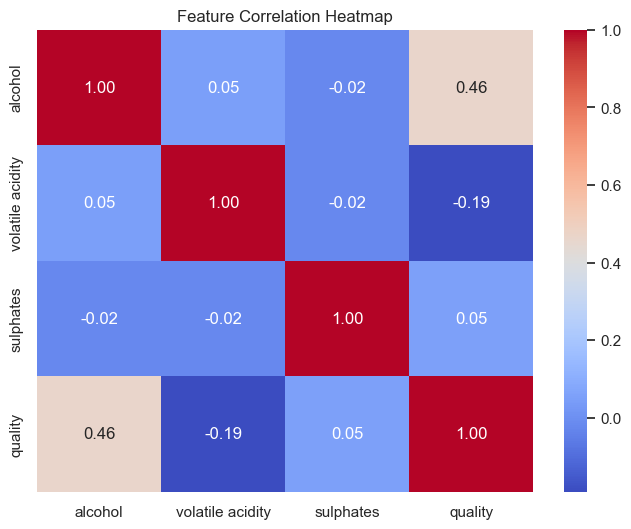

In [21]:
plt.figure(figsize=(8, 6))
correlation = df[features + [target]].corr()
sns.heatmap(correlation,annot=True,cmap="coolwarm",fmt=".2f")
plt.title("Feature Correlation Heatmap")
plt.show()

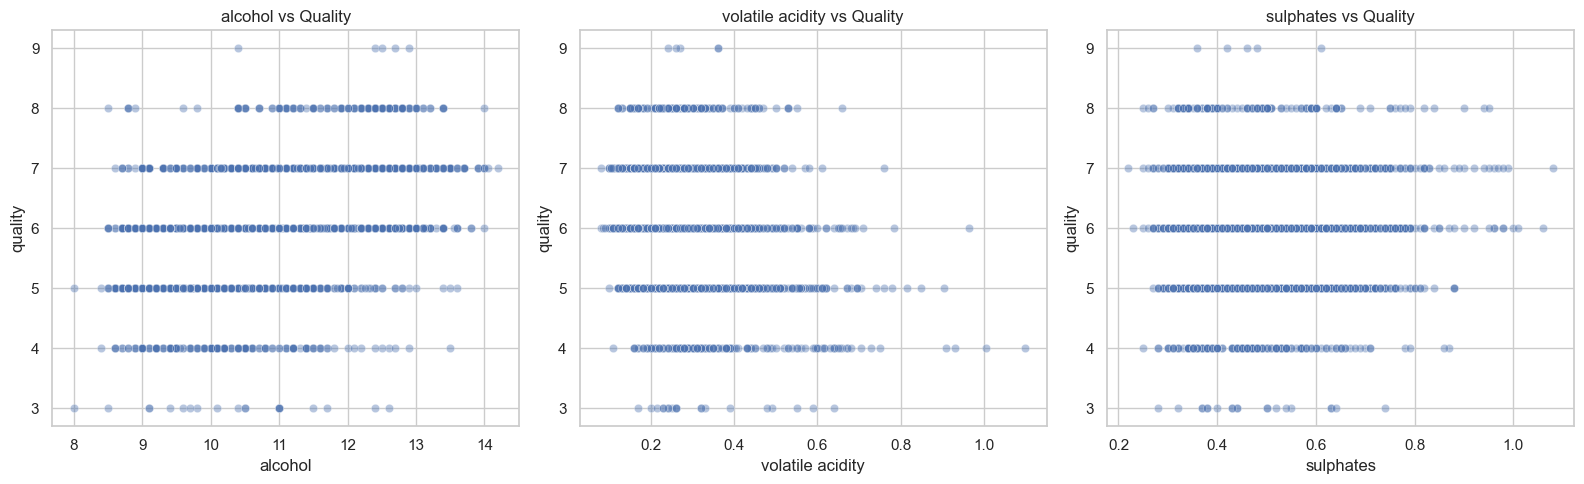

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i, feature in enumerate(features):
    sns.scatterplot(
        data=df,
        x=feature,
        y=target,
        alpha=0.4,
        ax=axes[i]
    )
    axes[i].set_title(f"{feature} vs Quality")

plt.tight_layout()
plt.show()

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)
print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

Training Samples: 3168
Testing Samples: 793


In [25]:
linear_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])
linear_model.fit(X_train, y_train)
linear_predictions = linear_model.predict(X_test)

In [27]:
linear_mae = mean_absolute_error(y_test, linear_predictions)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_predictions))
linear_r2 = r2_score(y_test, linear_predictions)
print("LINEAR REGRESSION RESULTS")
print("MAE:", round(linear_mae, 4))
print("RMSE:", round(linear_rmse, 4))
print("R2 Score:", round(linear_r2, 4))

LINEAR REGRESSION RESULTS
MAE: 0.6162
RMSE: 0.7951
R2 Score: 0.2292


In [29]:
degree = 2
poly_model = Pipeline([
    ("polynomial", PolynomialFeatures(degree=degree, include_bias=False)),
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])
poly_model.fit(X_train, y_train)
poly_predictions = poly_model.predict(X_test)

In [30]:
poly_transformer = PolynomialFeatures(degree=degree,include_bias=False
)
X_train_poly = poly_transformer.fit_transform(X_train)
print("Original Number of Features:", X_train.shape[1])
print("Polynomial Number of Features:", X_train_poly.shape[1])
print("\nGenerated Polynomial Features:")
print(poly_transformer.get_feature_names_out(features))

Original Number of Features: 3
Polynomial Number of Features: 9

Generated Polynomial Features:
['alcohol' 'volatile acidity' 'sulphates' 'alcohol^2'
 'alcohol volatile acidity' 'alcohol sulphates' 'volatile acidity^2'
 'volatile acidity sulphates' 'sulphates^2']


In [32]:
poly_mae = mean_absolute_error(y_test, poly_predictions)
poly_rmse = np.sqrt(mean_squared_error(y_test, poly_predictions))
poly_r2 = r2_score(y_test, poly_predictions)
print("POLYNOMIAL REGRESSION RESULTS")
print("MAE:", round(poly_mae, 4))
print("RMSE:", round(poly_rmse, 4))
print("R2 Score:", round(poly_r2, 4))

POLYNOMIAL REGRESSION RESULTS
MAE: 0.6187
RMSE: 0.8001
R2 Score: 0.2195


In [34]:
comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Polynomial Regression"],
    "MAE": [linear_mae, poly_mae],
    "RMSE": [linear_rmse, poly_rmse],
    "R2 Score": [linear_r2, poly_r2]
})
display(comparison.round(4))

,Model,MAE,RMSE,R2 Score
0,Linear Regression,0.6162,0.7951,0.2292
1,Polynomial Regression,0.6187,0.8001,0.2195


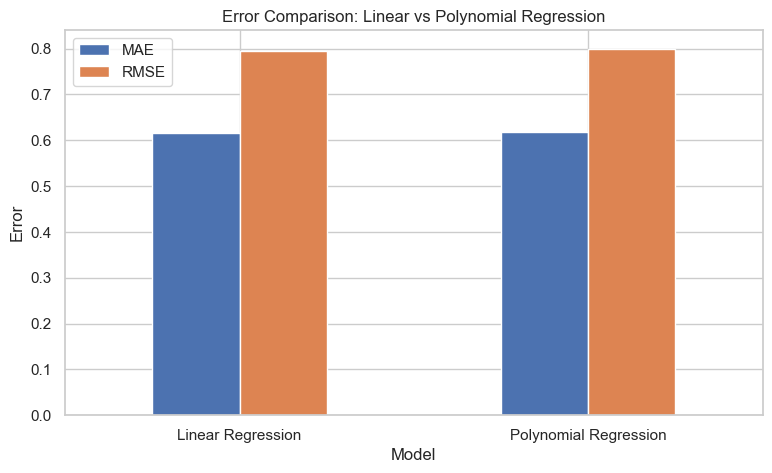

In [36]:
comparison_plot = comparison.set_index("Model")
comparison_plot[["MAE", "RMSE"]].plot(
    kind="bar",
    figsize=(9, 5)
)
plt.title("Error Comparison: Linear vs Polynomial Regression")
plt.ylabel("Error")
plt.xticks(rotation=0)
plt.show()

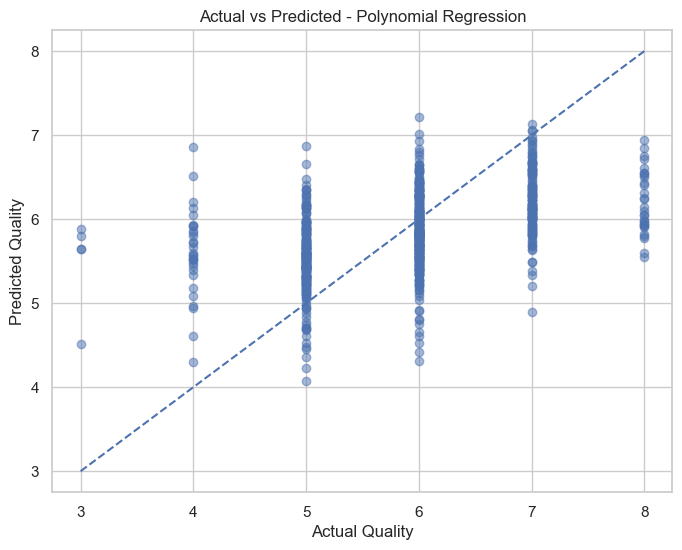

In [38]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test,poly_predictions,alpha=0.5)
min_value = min(y_test.min(), poly_predictions.min())
max_value = max(y_test.max(), poly_predictions.max())
plt.plot([min_value, max_value],[min_value, max_value],linestyle="--")
plt.xlabel("Actual Quality")
plt.ylabel("Predicted Quality")
plt.title("Actual vs Predicted - Polynomial Regression")
plt.show()

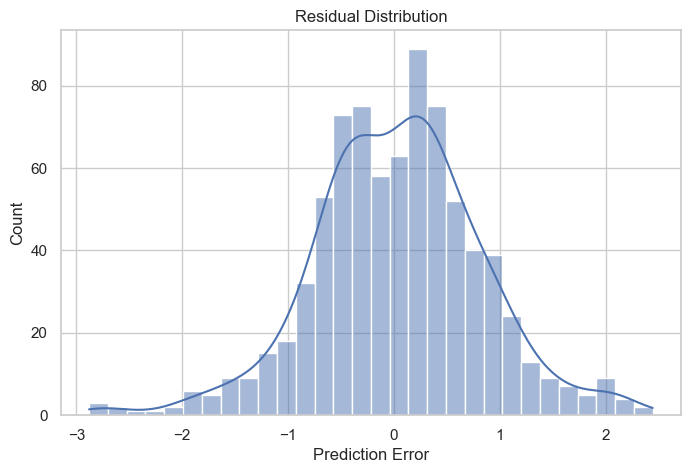

In [40]:
residuals = y_test - poly_predictions
plt.figure(figsize=(8, 5))
sns.histplot(residuals, kde=True, bins=30)
plt.title("Residual Distribution")
plt.xlabel("Prediction Error")
plt.show()

In [41]:
degree_results = []
for d in range(1, 5):
    model = Pipeline([("polynomial", PolynomialFeatures(degree=d, include_bias=False)),("scaler", StandardScaler()),("model", LinearRegression())])
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    degree_results.append({
        "Degree": d,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2 Score": r2_score(y_test, predictions)
    })
degree_comparison = pd.DataFrame(degree_results)
display(degree_comparison.round(4))

,Degree,MAE,RMSE,R2 Score
0,1,0.6162,0.7951,0.2292
1,2,0.6187,0.8001,0.2195
2,3,0.6160,0.7933,0.2327
3,4,0.6201,0.7939,0.2316


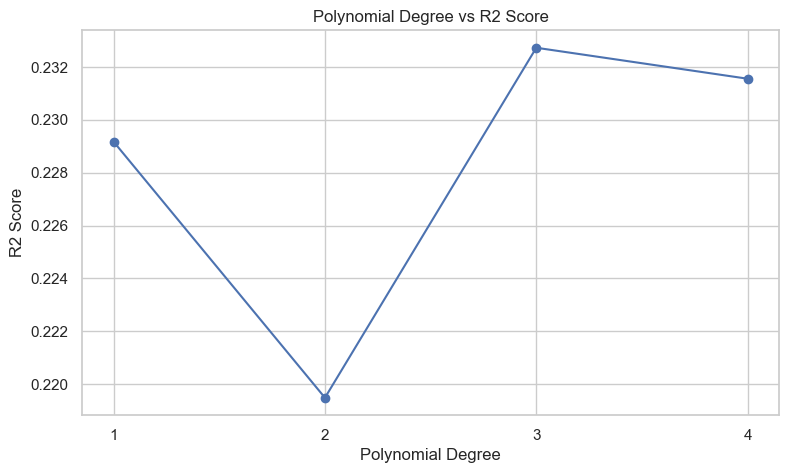

In [42]:
plt.figure(figsize=(9, 5))
plt.plot(
    degree_comparison["Degree"],
    degree_comparison["R2 Score"],
    marker="o"
)
plt.title("Polynomial Degree vs R2 Score")
plt.xlabel("Polynomial Degree")
plt.ylabel("R2 Score")
plt.xticks([1, 2, 3, 4])
plt.show()

In [43]:
sample = pd.DataFrame({
    "alcohol": [10.5],
    "volatile acidity": [0.30],
    "sulphates": [0.45]
})
predicted_quality = poly_model.predict(sample)
print("Predicted Wine Quality:", round(predicted_quality[0], 2))

Predicted Wine Quality: 5.69


In [46]:
print("SUMMARY")
print("Dataset:", "Wine Quality - White")
print("Total Rows After Cleaning:", len(df))
print("Selected Features:", features)
print("Target Variable:", target)
print("Linear Regression R2:", round(linear_r2, 4))
print("Polynomial Regression R2:", round(poly_r2, 4))
print("MAE Improvement:",round(linear_mae - poly_mae, 4))
print("RMSE Improvement:",round(linear_rmse - poly_rmse, 4))

SUMMARY
Dataset: Wine Quality - White
Total Rows After Cleaning: 3961
Selected Features: ['alcohol', 'volatile acidity', 'sulphates']
Target Variable: quality
Linear Regression R2: 0.2292
Polynomial Regression R2: 0.2195
MAE Improvement: -0.0025
RMSE Improvement: -0.005
